# Aula 5 — Modelagem preditiva com Machine Learning e interpretação via SHAP
**Módulo `geocis_espectral.modelagem`** · tradução do pipeline R `mhpp_v4_updated.R`

**Fluxo**
1. Escolher o atributo-alvo e montar X (espectros) e y;
2. Dividir **calibração (treino)** e **validação (teste)** — estratificado por y;
3. Para cada **pré-processamento × algoritmo** (PLSR, Random Forest, XGBoost): busca de
   hiperparâmetros por **validação cruzada 5-fold** no treino;
4. Avaliar no teste (R², RMSE, RPD, RPIQ, CCC, viés);
5. Interpretar: **SHAP** (e VIP do PLS) — quais bandas o modelo usa, e isso faz sentido físico?

| Métrica | Definição | Leitura |
|---|---|---|
| R² | r² de Pearson obs × pred | proporção da variância explicada |
| RMSE | √média(pred − obs)² | erro na unidade do atributo |
| Bias | média(pred − obs) | erro sistemático |
| RPD | DP(obs)/RMSE | > 2 bom; 1,4–2 razoável |
| RPIQ | IIQ(obs)/RMSE | robusto a assimetria; > 2,7 bom (aprox.) |
| CCC | concordância de Lin | proximidade da reta 1:1 |

In [1]:
# --- Configuração (igual em todas as aulas) ---------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from geocis_espectral import dados, visualizacao as vz, processamento as pp
from geocis_espectral import exploratoria as ex, agrupamento as ag, modelagem as mo

vz.set_style()
pd.set_option("display.max_columns", 30)

# Base do GeoCiS: raw_nir_data_Saturin.csv + raw_mir_data_Saturin.csv.
# Na 1ª execução (ou se os CSV mudarem) a base pareada é preparada automaticamente (~30 s).
# Para demonstrações fora do GeoCiS, troque para FONTE = "synthetic".
FONTE = "paired"
ds = dados.load_dataset(FONTE)
ds

SoilSpectra(n=6230, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])

## 1. Alvo, dados e parâmetros

In [2]:
ALVO = "Clay_gkg"          # troque para "C_gkg", "pH_H2O", "Sand_gkg" ...
N_MAX = 1500               # nº máx. de amostras (acelera a aula; use None para todas)
BIN = 10                   # binning de bandas (10 -> ~205 variáveis)

base = ds.dropna_attribute(ALVO)
if N_MAX and len(base) > N_MAX:
    base = base.sample(N_MAX)
X = pp.binning(pp.trim(base.vnir, 400, 2450), BIN)
y = base.meta[ALVO]
print(f"{ALVO}: n = {len(y)}, X = {X.shape}")
y.describe().round(1)

Clay_gkg: n = 1500, X = (1500, 205)


count    1500.0
mean      310.5
std       209.2
min         0.0
25%       146.8
50%       283.8
75%       448.0
max       933.0
Name: Clay_gkg, dtype: float64

## 2. Quantas variáveis latentes no PLS?
O RMSE da validação cruzada cai até um ponto e depois estabiliza/sobe (sobreajuste).
A busca em grade (`GridSearchCV`) faz essa escolha automaticamente em cada modelo.

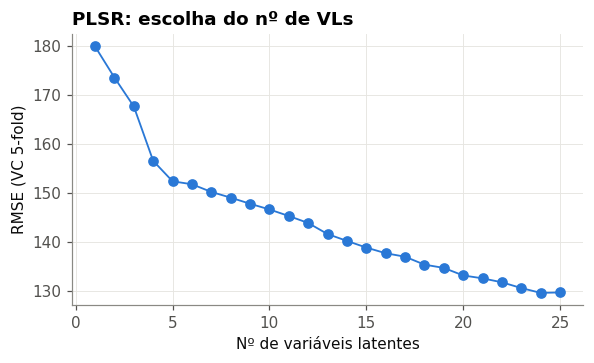

In [3]:
curva = mo.pls_cv_curve(X, y, preproc="snv", max_components=25)
ax = curva.plot(x="n_vl", y="RMSE", marker="o", figsize=(6, 3.2), legend=False, color=vz.CATEGORICAL[0])
ax.set(xlabel="Nº de variáveis latentes", ylabel="RMSE (VC 5-fold)")
ax.set_title("PLSR: escolha do nº de VLs", loc="left");

## 3. Comparação pré-processamento × algoritmo
Mesma partição treino/teste (80/20, estratificada) para todas as combinações.
O melhor modelo é escolhido pelo **menor RMSE da validação cruzada** — o script R escolhia
pelo R² do teste (use `select_by="R2_test"` para reproduzi-lo), o que usa o teste na seleção.

⏱️ Leva alguns minutos (Random Forest e XGBoost testam várias combinações de hiperparâmetros).

In [4]:
res = mo.compare_models(X, y, preprocs=("raw", "snv", "sg1d"), algos=("pls", "rf", "xgb"),
                        test_size=0.2, cv=5)
res.table.drop(columns="best_params").round(3)

       raw | pls  CV RMSE = 138.343 | R² teste = 0.641 (6 s)


       raw | rf   CV RMSE = 142.328 | R² teste = 0.548 (12 s)


       raw | xgb  CV RMSE = 140.759 | R² teste = 0.547 (21 s)


       snv | pls  CV RMSE = 135.315 | R² teste = 0.648 (2 s)


       snv | rf   CV RMSE = 141.031 | R² teste = 0.556 (12 s)


       snv | xgb  CV RMSE = 140.064 | R² teste = 0.570 (24 s)


      sg1d | pls  CV RMSE = 141.283 | R² teste = 0.627 (1 s)


      sg1d | rf   CV RMSE = 127.030 | R² teste = 0.644 (11 s)


      sg1d | xgb  CV RMSE = 119.273 | R² teste = 0.707 (26 s)


,Preprocessing,Algorithm,R2_train,RMSE_train,R2_test,RMSE_test,RPD,RPIQ,CCC,Bias,CV_RMSE,tempo_s
0,sg1d,xgb,0.992,19.924,0.707,109.732,1.839,2.497,0.818,7.636,119.273,25.6
1,sg1d,rf,0.956,52.228,0.644,121.675,1.658,2.252,0.761,10.677,127.030,11.4
2,snv,pls,0.661,122.830,0.648,120.378,1.676,2.276,0.790,12.464,135.315,2.3
3,raw,pls,0.622,129.733,0.641,120.974,1.668,2.265,0.787,6.168,138.343,5.5
4,snv,xgb,0.985,28.558,0.570,132.706,1.521,2.065,0.730,11.240,140.064,23.7
5,raw,xgb,0.968,41.505,0.547,136.452,1.479,2.008,0.717,11.370,140.759,21.3
6,snv,rf,0.943,58.644,0.556,134.906,1.496,2.031,0.703,11.892,141.031,12.3
7,sg1d,pls,0.608,132.133,0.627,123.442,1.635,2.220,0.778,6.945,141.283,1.2
8,raw,rf,0.939,60.253,0.548,136.029,1.483,2.014,0.710,12.356,142.328,11.5


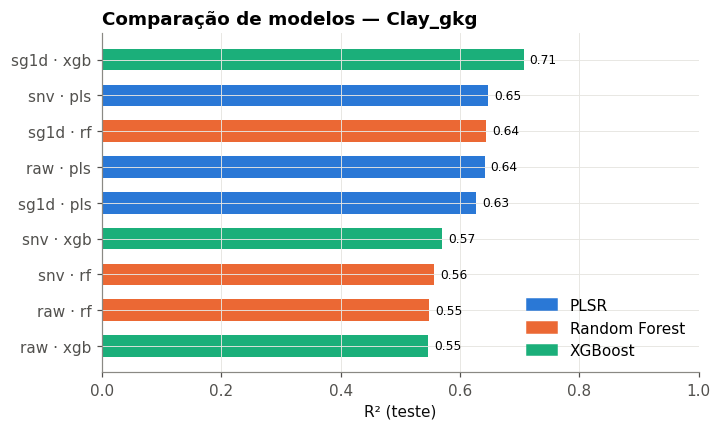

In [5]:
t = res.table.assign(metodo=lambda d: d["Preprocessing"] + " · " + d["Algorithm"]).sort_values("R2_test")
algos = ["pls", "rf", "xgb"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(t["metodo"], t["R2_test"], color=[vz.CATEGORICAL[algos.index(a)] for a in t["Algorithm"]], height=0.6)
for i, v in enumerate(t["R2_test"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=vz.CATEGORICAL[i]) for i in range(3)]
ax.legend(handles, ["PLSR", "Random Forest", "XGBoost"], loc="lower right")
ax.set(xlabel="R² (teste)", xlim=(0, 1)); ax.set_title(f"Comparação de modelos — {ALVO}", loc="left");

**Atenção ao sobreajuste:** compare `R2_train` com `R2_test`. Árvores (RF, XGBoost) quase
"decoram" o treino (R² ≈ 0,99) — por isso o desempenho só é avaliado na validação cruzada e no
teste. O PLS tem R² de treino e teste próximos: é menos flexível, porém mais estável.

Melhor (por CV): ('sg1d', 'xgb') | desempenho bom


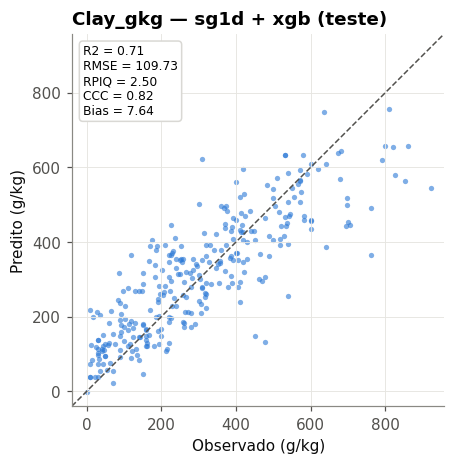

In [6]:
melhor = res.best_key
pred = res.predictions()
m = mo.metrics(pred["observado"], pred["predito"])
print("Melhor (por CV):", melhor, "| desempenho", mo.classify_performance(m["R2"]))
ax = vz.plot_obs_pred(pred["observado"], pred["predito"], metrics=m, unit="(g/kg)",
                      title=f"{ALVO} — {melhor[0]} + {melhor[1]} (teste)")

## 4. VIS–NIR–SWIR × MIR × fusão
Mesmo modelo (SNV + PLSR) com cada faixa e com as duas concatenadas
("VIS–NIR–SWIR seguido do MIR").

In [7]:
faixas = {
    "VIS-NIR-SWIR": X,
    "MIR": pp.binning(base.mir, 4),
}
faixas["Fusão VNIR+MIR"] = pd.concat([pp.snv(faixas["VIS-NIR-SWIR"]).add_prefix("v"),
                                      pp.snv(faixas["MIR"]).add_prefix("m")], axis=1)
linhas = []
for nome, Xf in faixas.items():
    prep = "raw" if nome.startswith("Fusão") else "snv"
    r = mo.compare_models(Xf, y, preprocs=(prep,), algos=("pls",), verbose=False)
    linhas.append({"faixa": nome, "variaveis": Xf.shape[1], **r.table.iloc[0][["R2_test", "RMSE_test", "RPIQ", "CV_RMSE"]]})
pd.DataFrame(linhas).round(3)

,faixa,variaveis,R2_test,RMSE_test,RPIQ,CV_RMSE
0,VIS-NIR-SWIR,205,0.648,120.378,2.276,135.315
1,MIR,212,0.710,108.482,2.526,112.409
2,Fusão VNIR+MIR,417,0.767,97.930,2.798,105.509


## 5. Interpretação com SHAP
**SHAP** (SHapley Additive exPlanations) distribui a predição de cada amostra entre as
variáveis: `predição = valor_base + Σ SHAP_banda`. A média de |SHAP| por banda é a
importância global; o sinal mostra se a banda puxa a predição para cima ou para baixo.

Para espectros, o gráfico mais útil é a **importância ao longo do comprimento de onda**,
comparada às feições de absorção conhecidas.

C:\Users\PC\Desktop\RESET\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


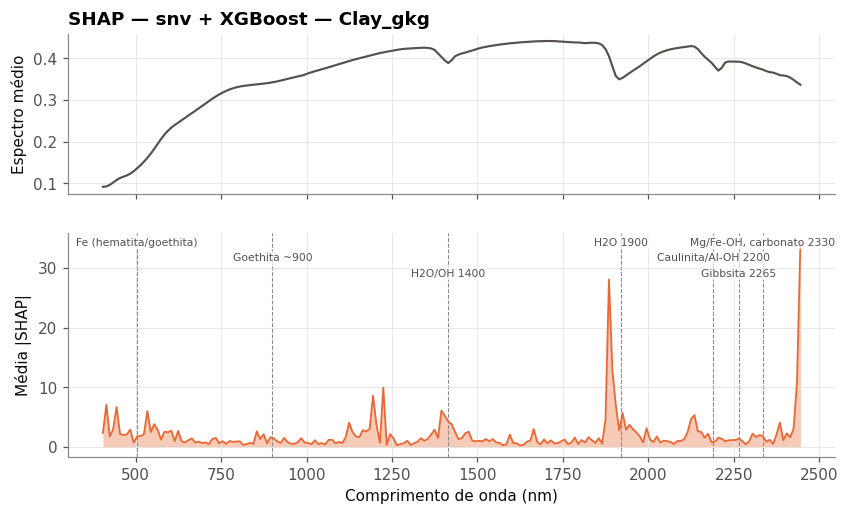

In [8]:
chave_xgb = ("snv", "xgb") if ("snv", "xgb") in res.models else next(k for k in res.models if k[1] == "xgb")
modelo_xgb = res.models[chave_xgb]
shap_xgb = mo.shap_values(modelo_xgb, res.X_test, X_background=res.X_train)
imp_xgb = mo.spectral_importance(shap_xgb)
axes = vz.plot_spectral_importance(imp_xgb, reference_spectrum=X.mean(),
                                   title=f"SHAP — {chave_xgb[0]} + XGBoost — {ALVO}")

In [9]:
# Verificação da aditividade: base + soma dos SHAP = predição do modelo
pred_xgb = modelo_xgb.predict(res.X_test.to_numpy())
print("diferença máx.:", np.abs(shap_xgb.attrs["base_value"] + shap_xgb.sum(axis=1) - pred_xgb).max().round(4))
mo.top_features(imp_xgb, 10).round(3)

diferença máx.: 0.0009


,banda,media_abs_shap
0,2444.5,34.178001
1,1884.5,28.044001
2,1894.5,12.882000
3,2434.5,10.994000
4,1224.5,9.945000
5,1194.5,8.591000
6,414.5,7.085000
7,1904.5,7.028000
8,444.5,6.691000
9,1394.5,6.077000


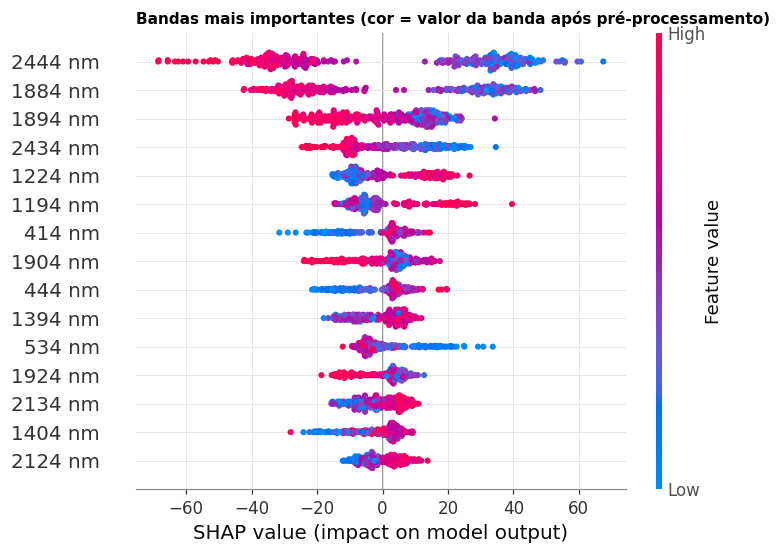

In [10]:
import shap
top = imp_xgb.sort_values(ascending=False).head(15).index
prep = modelo_xgb.named_steps["prep"]
Xt = res.X_test.to_numpy() if prep == "passthrough" else prep.transform(res.X_test.to_numpy())
cols = [list(X.columns).index(c) for c in top]
shap.summary_plot(shap_xgb[top].to_numpy(), Xt[:, cols], feature_names=[f"{c:.0f} nm" for c in top],
                  show=False, plot_size=(7, 5))
plt.title("Bandas mais importantes (cor = valor da banda após pré-processamento)", loc="left", fontsize=10);

### PLSR: SHAP exato e VIP
No PLS (linear), SHAP = coeficiente × (x − média). O **VIP** (*Variable Importance in
Projection*) é a medida clássica; bandas com VIP > 1 são consideradas relevantes.

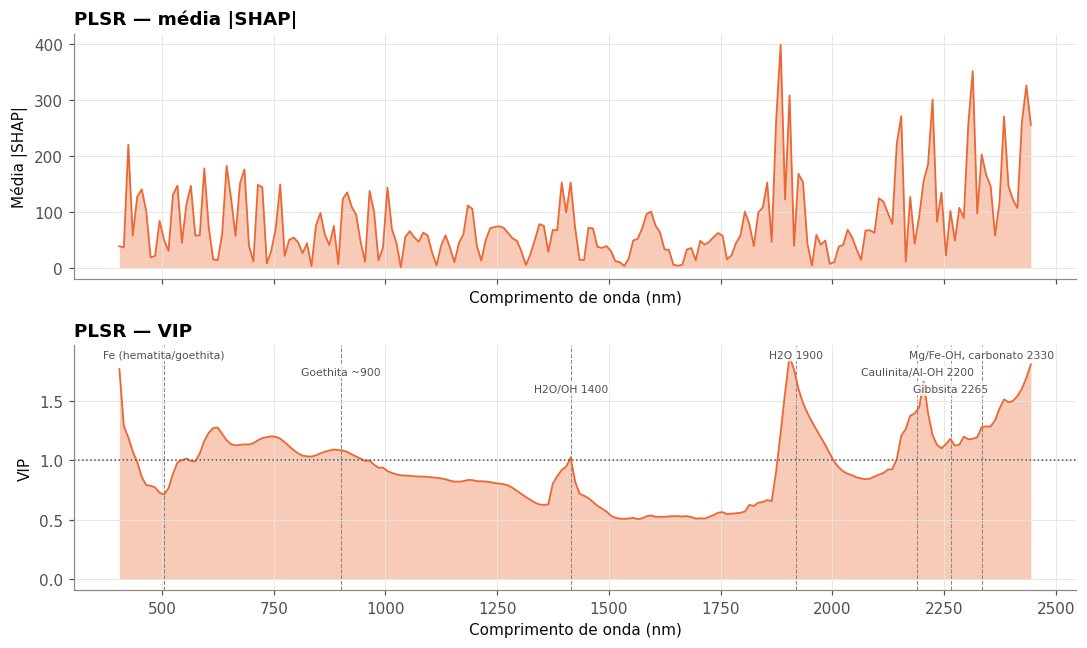

In [11]:
chave_pls = ("snv", "pls") if ("snv", "pls") in res.models else next(k for k in res.models if k[1] == "pls")
modelo_pls = res.models[chave_pls]
imp_pls = mo.spectral_importance(mo.shap_values(modelo_pls, res.X_test, res.X_train))
vip = pd.Series(mo.vip(modelo_pls.named_steps["model"]), index=X.columns)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
vz.plot_spectral_importance(imp_pls, ax=axes[0], title="PLSR — média |SHAP|", features=False)
vz.plot_spectral_importance(vip, ax=axes[1], ylabel="VIP", title="PLSR — VIP", features=True)
axes[1].axhline(1, color=vz.NEUTRAL, ls=":", lw=1)
fig.tight_layout()

**Pergunta-chave da interpretação:** as bandas importantes coincidem com feições conhecidas
(2200 nm Al-OH e 1900 nm água/argilominerais para argila; albedo e 1700/2300 nm para
carbono)? Se o modelo usa regiões sem significado físico, desconfie — pode estar
aprendendo efeitos de equipamento ou de origem da amostra.

## 6. Salvar, carregar e aplicar o modelo em novas amostras

In [12]:
caminho = mo.save_model(res.best_model, f"{ALVO}_{melhor[0]}_{melhor[1]}")
modelo = mo.load_model(caminho)
com_alvo = ds.dropna_attribute(ALVO)
novas = com_alvo.subset(~com_alvo.meta.index.isin(base.meta.index)).sample(5)   # fora da calibração
X_novas = pp.binning(pp.trim(novas.vnir, 400, 2450), BIN)
pd.DataFrame({"predito": np.ravel(modelo.predict(X_novas.to_numpy())).round(1),
              "observado": novas.meta[ALVO]}, index=novas.meta.index)

,predito,observado
73773,754.599976,785.0
217,555.400024,650.0
75147,262.500000,193.0
76931,407.899994,379.0
231756,70.199997,0.0


In [13]:
# Tabelas para o relatório
from geocis_espectral import config
saida = config.OUTPUT_DIR / "tabelas"
saida.mkdir(parents=True, exist_ok=True)
res.table.to_csv(saida / f"comparacao_modelos_{ALVO}.csv", index=False)
mo.top_features(imp_xgb, 20).to_csv(saida / f"shap_importancia_{ALVO}.csv", index=False)
print("salvo em", saida)

salvo em C:\Users\PC\Desktop\RESET\geocis-espectroscopia\outputs\tabelas


## Exercícios
1. Modele **carbono** (`C_gkg`). Dica: a distribuição é muito assimétrica — compare modelar
   `y` e `np.log1p(y)` (volte com `np.expm1` antes das métricas).
2. Rode `compare_models(..., select_by="R2_test")` e compare com a escolha por CV.
3. Repita a seção 5 com o **MIR**: as bandas importantes para argila coincidem com
   3695/3620 cm⁻¹ (OH da caulinita)?
4. Para o script completo equivalente ao R (com pastas de saída), veja
   `scripts/pipeline_modelagem.py`.